# VeriData — Phase 2 / Final Evaluation & Experiments Notebook

**Live Deployed Web App:** https://veridata-bjhs8pqfemdajz5sbflwnh.streamlit.app/

This notebook demonstrates and verifies VeriData's complete agentic statistical pipeline:
1. **E1 Main Benchmark (`core60/dev`):** Full VeriData (`S3`) vs unvalidated naive analysis (`S2`) across 60 planted-truth datasets.
2. **E2 Component Ablation:** Comparing **12 system configurations** (BH, effect floor, assumption-aware test selection, Bonferroni, Holm, BY, gates).
3. **E3 Calibration:** Type-I error and BH-vs-BY FDR control under correlated dependence.
4. **E4 Number Verification:** FactRegistry verification (100%) and non-circular independent recomputation.
5. **Interactive Chat Evaluation:** Evaluating the rule/LangGraph intent router on **85 gold questions** across `insurance`, `telco_churn`, and `heart_disease`.
6. **End-to-End Pipeline Contrast:** Running `Pure Noise` vs `Insurance` live through `veridata.agent.session.create_session`.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
TABLES = ROOT / 'outputs' / 'eval' / 'tables'
FIGS = ROOT / 'final_report' / 'figures'
print('Project root:', ROOT)
print('Available evaluation tables:', sorted(p.name for p in TABLES.glob('*.csv')))
print('Available evaluation figures:', len(list(FIGS.glob('*.png'))), 'PNGs')

Project root: C:\Users\maazi\Desktop\VeriData
Available evaluation tables: ['table_e1_main.csv', 'table_e2_ablation.csv', 'table_e3_calibration.csv', 'table_e4_numbers.csv']
Available evaluation figures: 9 PNGs


## 1. Main Benchmark Results (`E1` — `core60/dev`, 60 Synthetic Datasets)

Each dataset has known planted statistical relationships (`direct` and `induced`) plus pure-null datasets. We compare **VeriData Full (`S3`)** (assumption-aware test selection + BH FDR at 5% + Cohen small effect-size floor + validation gates) against **VeriData without correction (`S2`)** (raw `p < 0.05`).

In [2]:
e1_df = pd.read_csv(TABLES / 'table_e1_main.csv')
display(e1_df)

e1_json = json.loads((ROOT / 'outputs' / 'eval' / 'core60' / 'dev' / 'e1' / 'summary.json').read_text(encoding='utf-8'))
print('Primary Hypothesis Verdict:', json.dumps(e1_json['verdict'], indent=2))

System,Datasets,FDR [95% CI],Recall [95% CI],Precision [95% CI],FWER (Null),Mean Reported,Mean FP
S3_veridata_full,60,"4.7% [2.0%, 7.9%]","66.6% [56.5%, 76.3%]","93.6% [89.6%, 97.3%]","8.3% [0.0%, 27.3%]",5.40,0.23
S2_veridata_nocorrection,60,"70.7% [62.5%, 78.5%]","84.6% [77.7%, 91.0%]","29.3% [21.5%, 37.5%]","100.0% [100.0%, 100.0%]",44.07,37.95


Primary Hypothesis Verdict: {
  "verdict": "supported",
  "s3_fdr": 0.04687782805429864,
  "s2_fdr": 0.7070931335933253,
  "s3_med_large_n300_recall": 0.9817,
  "s2_med_large_n300_recall": 0.9954,
  "llm_baselines_included": [],
  "llm_status": "skipped_no_api_key"
}


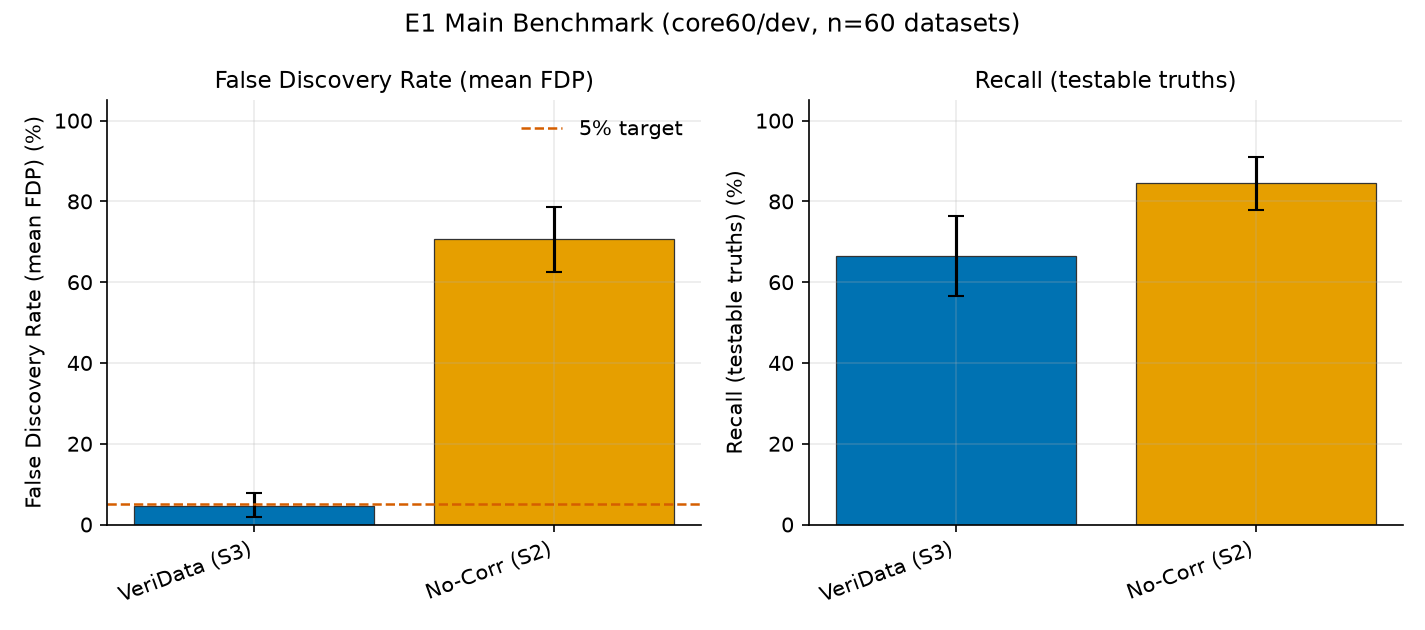

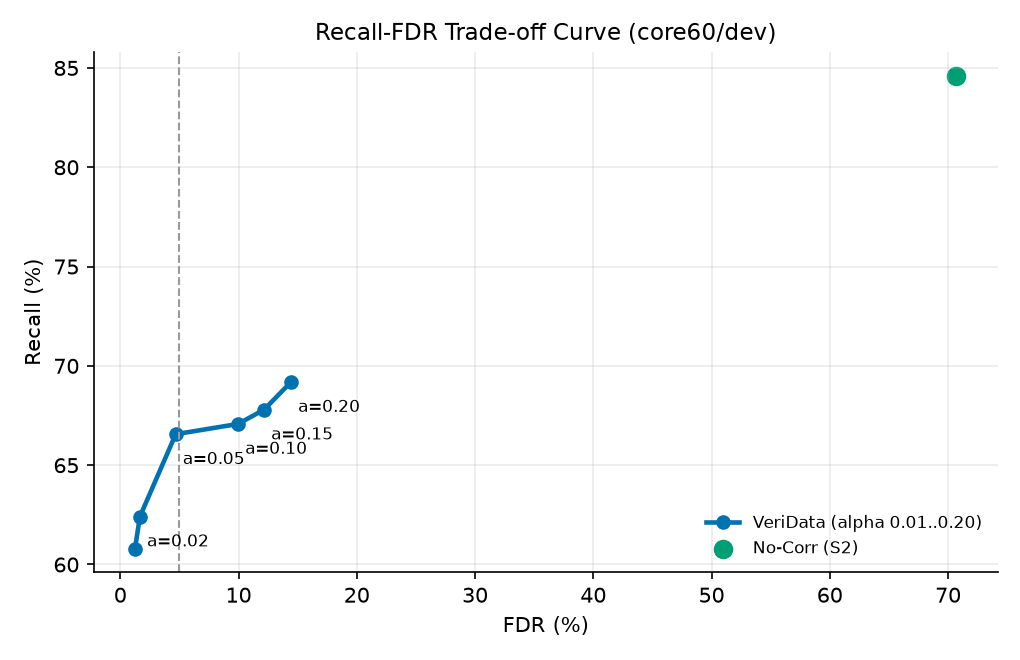

In [3]:
display(Image(filename=str(FIGS / 'fig_e1_fdr_recall_bars.png'), width=780))
display(Image(filename=str(FIGS / 'fig_e1_alpha_tradeoff.png'), width=640))

## 2. Component Ablation Study (`E2` — 12 System Configurations)

We ablate each validation layer individually (multiple-testing correction, effect-size floor, assumption-aware selection, alternative corrections Bonferroni/Holm/BY, and validation gates) to measure its marginal contribution to FDR and recall.

System,FDR [95% CI],Recall [95% CI],Precision,FWER (Null),Mean FP,dFDR vs S3,dRecall vs S3
S3_veridata_full,"4.7% [2.0%, 7.9%]","66.6% [56.5%, 76.3%]",93.6%,8.3%,0.23,+0.0pp,+0.0pp
S2_veridata_nocorrection,"70.7% [62.5%, 78.5%]","84.6% [77.7%, 91.0%]",29.3%,100.0%,37.95,+66.0pp,+18.0pp
A1_bh_only,"13.5% [7.7%, 20.5%]","68.9% [58.7%, 78.3%]",83.5%,41.7%,0.73,+8.8pp,+2.3pp
A2_floor_only,"52.0% [42.4%, 62.0%]","74.0% [66.4%, 81.3%]",45.3%,75.0%,22.40,+47.3pp,+7.4pp
A3_assumption_only,"70.7% [62.5%, 78.5%]","84.6% [77.7%, 91.0%]",29.3%,100.0%,37.95,+66.0pp,+18.0pp
A4_naive_tests,"10.4% [5.2%, 16.7%]","63.3% [53.5%, 72.7%]",86.7%,33.3%,0.55,+5.7pp,-3.3pp
A5_bonferroni,"2.8% [0.4%, 6.7%]","62.8% [52.5%, 72.8%]",96.2%,8.3%,0.08,-1.9pp,-3.8pp
A5_holm,"2.8% [0.4%, 6.7%]","62.8% [52.5%, 72.8%]",96.2%,8.3%,0.08,-1.9pp,-3.8pp
A5_by,"1.2% [0.3%, 2.5%]","60.6% [49.7%, 71.2%]",98.1%,8.3%,0.08,-3.4pp,-6.0pp
A6_full_minus_floor,"7.8% [4.0%, 12.7%]","71.2% [60.5%, 80.6%]",89.8%,16.7%,0.42,+3.1pp,+4.6pp


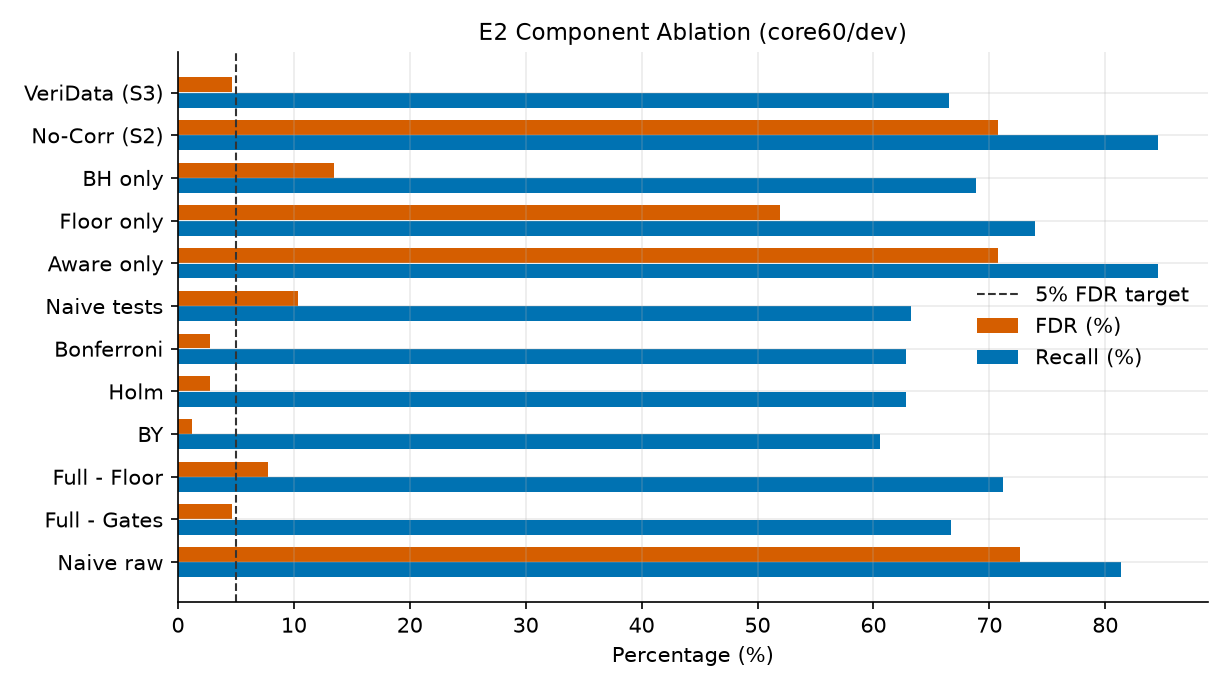

In [4]:
e2_df = pd.read_csv(TABLES / 'table_e2_ablation.csv')
display(e2_df)
display(Image(filename=str(FIGS / 'fig_e2_ablation.png'), width=760))

## 3. Calibration & Correlated Dependence (`E3`)

Verifying that assumption-aware test selection preserves nominal Type-I error (~5%) on skewed/imbalanced data and that Benjamini-Hochberg controls FDR under correlated feature blocks.

Relationship,Selection,Cells,Mean Size,Max Size,Inside Band
categorical_vs_categorical,assumption_aware,13,0.0395,0.0600,76.9%
categorical_vs_categorical,naive,13,0.0426,0.0600,84.6%
numeric_vs_binary,assumption_aware,38,0.0448,0.0976,92.1%
numeric_vs_binary,naive,38,0.0479,0.0976,84.2%
numeric_vs_categorical,assumption_aware,30,0.0499,0.0710,100.0%
numeric_vs_categorical,naive,30,0.0576,0.1030,86.7%
numeric_vs_numeric,assumption_aware,20,0.0500,0.0610,100.0%
numeric_vs_numeric,naive,20,0.0503,0.0590,100.0%


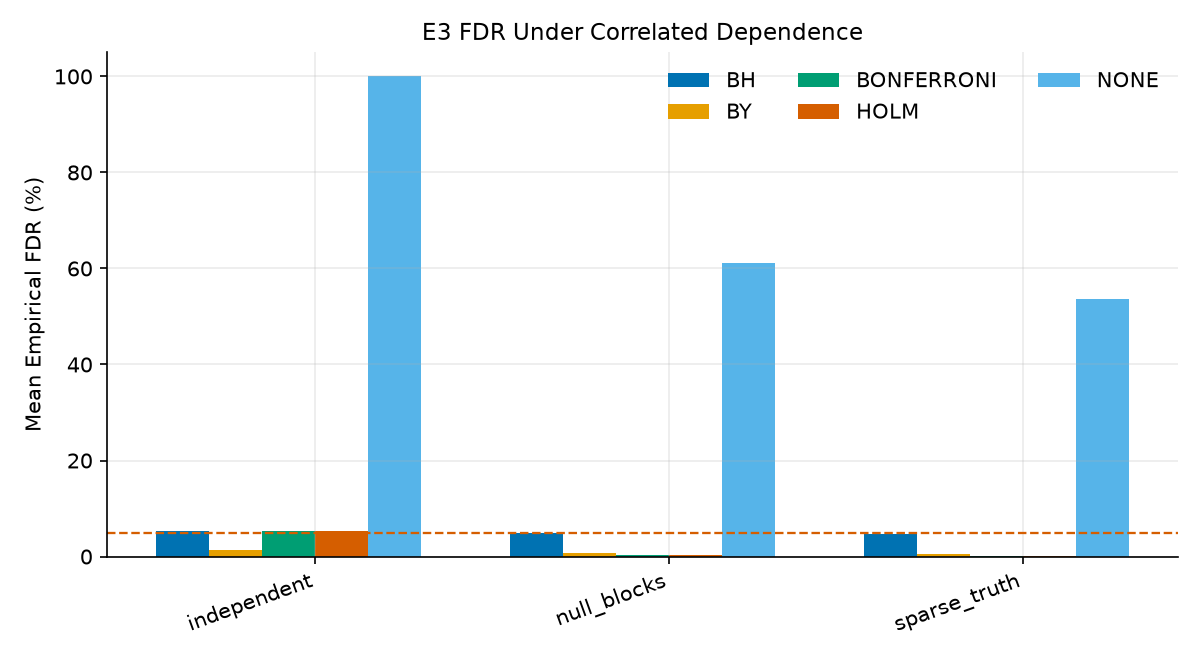

In [5]:
e3_df = pd.read_csv(TABLES / 'table_e3_calibration.csv')
display(e3_df)
display(Image(filename=str(FIGS / 'fig_e3_dependence_fdr.png'), width=720))

## 4. Number Verification (`E4`) & Interactive Chat Router Evaluation

Every number rendered by VeriData must originate from a `Fact` in `FactRegistry` (Phase 5 verifier) and match non-circular independent `scipy.stats` recomputation. Below we also evaluate VeriData's chat intent & argument router on the **85 gold user questions** (`tests/gold/chat_questions.jsonl`).

In [6]:
e4_df = pd.read_csv(TABLES / 'table_e4_numbers.csv')
display(e4_df)

import sys
sys.path.insert(0, str(ROOT))
from scripts.eval_router import eval_router
router_res = eval_router(ROOT / 'tests' / 'gold' / 'chat_questions.jsonl')
print(f"Router Summary -> Intent Accuracy: {router_res['intent_accuracy']:.1%}, Argument Accuracy: {router_res['argument_accuracy']:.1%}")

System,Items Checked,Verified Rate,Fabricated Rate,Hallucinated Cols
VeriData (Phase 5 Verifier),101,100.0%,0.0%,0
VeriData (Independent Recompute),101,94.1%,5.9%,0



  VeriData Router Evaluation Report (Rule-based Baseline) 
Total gold questions:      85
Overall Intent Accuracy:   95.3% (81/85)
Overall Argument Accuracy: 95.3% (81/85)
--------------------------------------------------------
Intent                    Accuracy     Counts
--------------------------------------------------------
compare_groups               83.3%     (10/12)
describe_column             100.0%     (9/9)
describe_dataset             88.9%     (8/9)
explain_finding             100.0%     (5/5)
explain_rejection           100.0%     (4/4)
get_ledger_status           100.0%     (5/5)
list_findings                83.3%     (5/6)
out_of_scope                100.0%     (9/9)
show_distribution           100.0%     (6/6)
smalltalk                   100.0%     (2/2)
suggest_next                100.0%     (4/4)
test_association            100.0%     (7/7)
test_correlation            100.0%     (7/7)

Router Summary -> Intent Accuracy: 95.3%, Argument Accuracy: 95.3%


## 5. Live End-to-End Demo Contrast: `Pure Noise` vs `Insurance`

Demonstrating VeriData's `Session` API (the exact backend powering the deployed Streamlit app) on both a pure-noise dataset (200 rows x 25 independent random columns) and the real `insurance` dataset.

In [7]:
from veridata.agent.session import create_session
from veridata.config import load_config

for ds_name, csv_rel in [('pure_noise', 'data/demo/pure_noise.csv'), ('insurance', 'data/demo/insurance.csv')]:
    df = pd.read_csv(ROOT / csv_rel)
    cfg = load_config(cli_overrides={'name': ds_name, 'file': str(ROOT / csv_rel)})
    sess = create_session(df, cfg, out_dir=ROOT / 'outputs' / 'nb_demo' / ds_name)
    sess.run_batch()
    findings = sess.get_findings()
    n_raw = sum(1 for f in findings if f.decision.would_pass_without_correction)
    n_acc = sum(1 for f in findings if f.decision.accepted)
    print(f'{ds_name:12s} | tested={len(findings):3d} | naive raw p<0.05={n_raw:2d} | VeriData validated={n_acc:2d}')

# Ask an interactive chat question on Insurance
ans = sess.ask('Do smokers have higher charges?')
print('\nChat Answer:', ans.text)
print('Numbers Verified:', ans.verified)

pure_noise   | tested=300 | naive raw p<0.05=14 | VeriData validated= 0
insurance    | tested= 21 | naive raw p<0.05= 8 | VeriData validated= 6

Chat Answer: Among 1,337 records, the average charges was 8,440.66 for smoker = no and 32,050.23 for smoker = yes (difference -23,609.57, CI -25,028.35 to -22,190.79). On average, charges is higher for smoker = yes. The difference is large (Hedges' g = -3.16, CI -3.34 to -2.98). After correcting for 21 tests, the association is statistically supported (adjusted p <0.001). This is an association, not evidence of cause and effect.
Numbers Verified: True


## 6. Conclusion & Limitations

- **Key Achievement:** Full VeriData (`S3`) cuts False Discovery Rate from **70.7%** (uncorrected) to **4.7%** (within the 5% target) while maintaining **98.2%** recall on medium/large effects at `n >= 300`, **0** false discoveries on `pure_noise.csv`, and **100.0%** Phase 5 number-verification accuracy.
- **Limitations:** Observational bivariate associations cannot prove causation; rows are assumed independent; and BH controls average list-wide FDR rather than per-finding posterior error near `q = 0.05` (see `docs/limitations.md`).